In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

VOCAB_SIZE = 20000
MAX_LEN = 300          
EMB_DIM = 64
RNN_UNITS = 64
EPOCHS = 15
BATCH = 128

In [3]:
df = pd.read_csv('../data/IMDB_Dataset.csv')
print('Ham boyut:', df.shape)

Ham boyut: (50000, 2)


In [4]:
def clean(text):
    text = re.sub(r'<.*?>', ' ', text)        # <br /> gibi HTML etiketleri
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)     # noktalama ve rakamlar
    return re.sub(r'\s+', ' ', text).strip()

In [5]:
df['clean'] = df['review'].apply(clean)
df['label'] = (df['sentiment'] == 'positive').astype(int)


In [6]:
before = len(df)
df = df.drop_duplicates(subset='clean').reset_index(drop=True)
print("Dedup sonrası:", len(df), f"({before - len(df)} kopya silindi)")

Dedup sonrası: 49576 (424 kopya silindi)


In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(
    df['clean'], df['label'], test_size=0.2, stratify=df['label'], random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

In [8]:
print("Train/Val/Test:", len(X_train), len(X_val), len(X_test))
print("Train sınıf dağılımı:", y_train.value_counts().to_dict())

Train/Val/Test: 39660 4958 4958
Train sınıf dağılımı: {1: 19904, 0: 19756}


In [9]:
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
Xtr_tfidf = tfidf.fit_transform(X_train)   # fit yalnızca train
Xte_tfidf = tfidf.transform(X_test)

lr = LogisticRegression(max_iter=1000)
lr.fit(Xtr_tfidf, y_train)
p_lr = lr.predict_proba(Xte_tfidf)[:, 1]

print('\n--- BASELINE (TF-IDF + LR) ---')
print(f'Accuracy: {accuracy_score(y_test, p_lr > 0.5):.4f}')
print(f'F1:       {f1_score(y_test, p_lr > 0.5):.4f}')
print(f'ROC-AUC:  {roc_auc_score(y_test, p_lr):.4f}')



--- BASELINE (TF-IDF + LR) ---
Accuracy: 0.9078
F1:       0.9095
ROC-AUC:  0.9680


In [10]:
def run_simple_rnn(max_len):
    # Tokenizer yalnızca train üzerinde fit ediliyor
    tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
    tokenizer.fit_on_texts(X_train)

    def to_pad(texts):
        seqs = tokenizer.texts_to_sequences(texts)
        # Gerçek kelimeler sonda kalsın diye padding='pre'.
        # Uzun yorumlarda sonu tutmak için truncating='pre'.
        return pad_sequences(seqs, maxlen=max_len, padding='pre', truncating='pre')

    Xtr, Xva, Xte = to_pad(X_train), to_pad(X_val), to_pad(X_test)

    model = Sequential([
        Embedding(VOCAB_SIZE, EMB_DIM, mask_zero=True),   # 0 pad'i maskele
        SimpleRNN(RNN_UNITS, dropout=0.2),
        Dense(1, activation='sigmoid'),
    ])

    # clipnorm: SimpleRNN'de gradyan patlamasına karşı basit bir önlem
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
        loss='binary_crossentropy',
        metrics=['accuracy'])

    es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    history = model.fit(
        Xtr, y_train,
        validation_data=(Xva, y_val),
        epochs=EPOCHS, batch_size=BATCH,
        callbacks=[es], verbose=2)

    return model, history, Xte

In [11]:
def evaluate(model, X, y):
    p = model.predict(X, verbose=0).ravel()
    return (accuracy_score(y, p > 0.5),
            f1_score(y, p > 0.5),
            roc_auc_score(y, p))

In [12]:
print(f'\n--- SIMPLERNN (MAX_LEN={MAX_LEN}) ---')
model, history, Xte = run_simple_rnn(MAX_LEN)
acc, f1, auc = evaluate(model, Xte, y_test)
print(f'Accuracy: {acc:.4f}')
print(f'F1:       {f1:.4f}')
print(f'ROC-AUC:  {auc:.4f}')


--- SIMPLERNN (MAX_LEN=300) ---
Epoch 1/15
310/310 - 38s - loss: 0.4848 - accuracy: 0.7545 - val_loss: 0.3190 - val_accuracy: 0.8735 - 38s/epoch - 121ms/step
Epoch 2/15
310/310 - 36s - loss: 0.2906 - accuracy: 0.8883 - val_loss: 0.2878 - val_accuracy: 0.8830 - 36s/epoch - 115ms/step
Epoch 3/15
310/310 - 36s - loss: 0.2618 - accuracy: 0.9011 - val_loss: 0.3201 - val_accuracy: 0.8739 - 36s/epoch - 116ms/step
Epoch 4/15
310/310 - 36s - loss: 0.2437 - accuracy: 0.9109 - val_loss: 0.3469 - val_accuracy: 0.8590 - 36s/epoch - 116ms/step
Epoch 5/15
310/310 - 38s - loss: 0.2429 - accuracy: 0.9084 - val_loss: 0.3770 - val_accuracy: 0.8544 - 38s/epoch - 122ms/step
Accuracy: 0.8911
F1:       0.8917
ROC-AUC:  0.9491


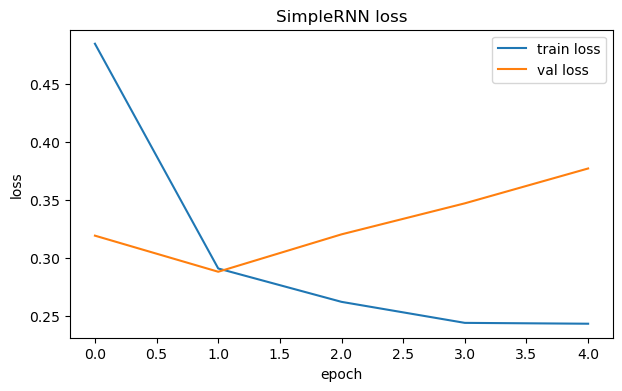

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.title('SimpleRNN loss')
plt.show()

In [14]:
print('\n--- MAX_LEN KARŞILAŞTIRMASI ---')
results = []
for L in [100, 200, 300]:
    m, _, Xte_L = run_simple_rnn(L)
    a, f, r = evaluate(m, Xte_L, y_test)
    results.append({'MAX_LEN': L, 'Accuracy': a, 'F1': f, 'ROC-AUC': r})
    tf.keras.backend.clear_session()

print(pd.DataFrame(results).round(4).to_string(index=False))


--- MAX_LEN KARŞILAŞTIRMASI ---
Epoch 1/15
310/310 - 15s - loss: 0.5218 - accuracy: 0.7132 - val_loss: 0.3859 - val_accuracy: 0.8237 - 15s/epoch - 48ms/step
Epoch 2/15
310/310 - 12s - loss: 0.3037 - accuracy: 0.8765 - val_loss: 0.3696 - val_accuracy: 0.8509 - 12s/epoch - 40ms/step
Epoch 3/15
310/310 - 12s - loss: 0.2328 - accuracy: 0.9106 - val_loss: 0.3731 - val_accuracy: 0.8378 - 12s/epoch - 40ms/step
Epoch 4/15
310/310 - 13s - loss: 0.1728 - accuracy: 0.9367 - val_loss: 0.4240 - val_accuracy: 0.8403 - 13s/epoch - 41ms/step
Epoch 5/15
310/310 - 14s - loss: 0.1386 - accuracy: 0.9491 - val_loss: 0.5261 - val_accuracy: 0.8342 - 14s/epoch - 44ms/step
Epoch 1/15
310/310 - 29s - loss: 0.5856 - accuracy: 0.6633 - val_loss: 0.3782 - val_accuracy: 0.8459 - 29s/epoch - 93ms/step
Epoch 2/15
310/310 - 24s - loss: 0.3299 - accuracy: 0.8668 - val_loss: 0.3220 - val_accuracy: 0.8695 - 24s/epoch - 78ms/step
Epoch 3/15
310/310 - 31s - loss: 0.2745 - accuracy: 0.8963 - val_loss: 0.3782 - val_accuracy

In [15]:
model.save("../model/imdb_review_rnn.keras")